# KCS rt: demo cases → KCS v23 on the rt system → plots → latency

Tech validation, not contract delivery.

- Real C++ only: rt-audio Project 3 `Engine`/`ProcessingWorker` + `release/kcs` (KCS v23 port) via `kcs_bridge` (`notebook/kcs_bridge.cpp`). Python = build, I/O, plots.
- Input: `../KCS_demo_20261102_48k` (6 cases, 48 kHz mono 16-bit, 6 s). Files are scaled by the manifest `gain`; `kcs_rt.load_demo()` divides it back → original level (the detector is level-dependent: S ≥ −5 dBFS selects W=256).
- Processor sees **only the mix** (`01_input_mix`). `03_clean` / `04_key` are references for plots and metrics; clean is also run through the same processor (fresh instance) for D1 KSR, as the KCS scorer does.
- Signal path: mic → callback → Q_in (SPSC) → worker: 48k→16k FIR → `TransientAR32` → 16k→48k FIR → Q_out → callback plays at a fixed delay; late/missing blocks → aligned dry.
- Default hop = callback = 32 frames → delay 544 frames (11.33 ms); hop 128 → 640 (13.33 ms). Output samples are identical for every hop (§4d).
- Open loop (no acoustic feedback in this problem). Material is synthetic (TinySOL + synthetic clicks, 16 kHz source upsampled → nothing above 8 kHz).

In [1]:
# 0. build: make libs + compile kcs_bridge
import sys, time
from pathlib import Path
here = next(p for p in [Path.cwd(), Path.cwd() / "notebook"] if (p / "kcs_rt.py").exists())
sys.path.insert(0, str(here))
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Audio, HTML, display
from scipy.signal import resample_poly
import kcs_rt as K
print(K.build())
CASES = K.load_demo()
SCORE, KCS_HEAD = K.scorer()
COLORS = {"mix": "tab:red", "kcs": "tab:blue", "clean": "0.5", "key": "tab:orange"}
print("KCS scorer @", KCS_HEAD)
for n, c in CASES.items():
    print(f"{n:28s} gain {c['gain']:.4f}  peak mix {np.abs(c['mix']).max():.3f}  frozen triggers {c['frozen_triggers']}")

/Users/fuchienzou/Documents/Quencher/rt-audio/build/notebook/kcs_bridge
KCS scorer @ ce6237c
snr0_sparse_in_gap_t1        gain 0.0604  peak mix 14.905  frozen triggers 4
snr5_dense_over_tone_t1      gain 0.1350  peak mix 6.667  frozen triggers 8
snr10_sparse_over_tone_t1    gain 0.1084  peak mix 8.303  frozen triggers 2
snr15_dense_in_gap_t3        gain 0.2053  peak mix 4.383  frozen triggers 4
snr20_sparse_in_gap_t2       gain 0.2754  peak mix 3.268  frozen triggers 3
snr20_dense_over_tone_t1     gain 0.4833  peak mix 1.862  frozen triggers 6


## 1. demo data

Mix = clean + key (both references). Markers = key-layer onsets (reference only, the processor never sees them).

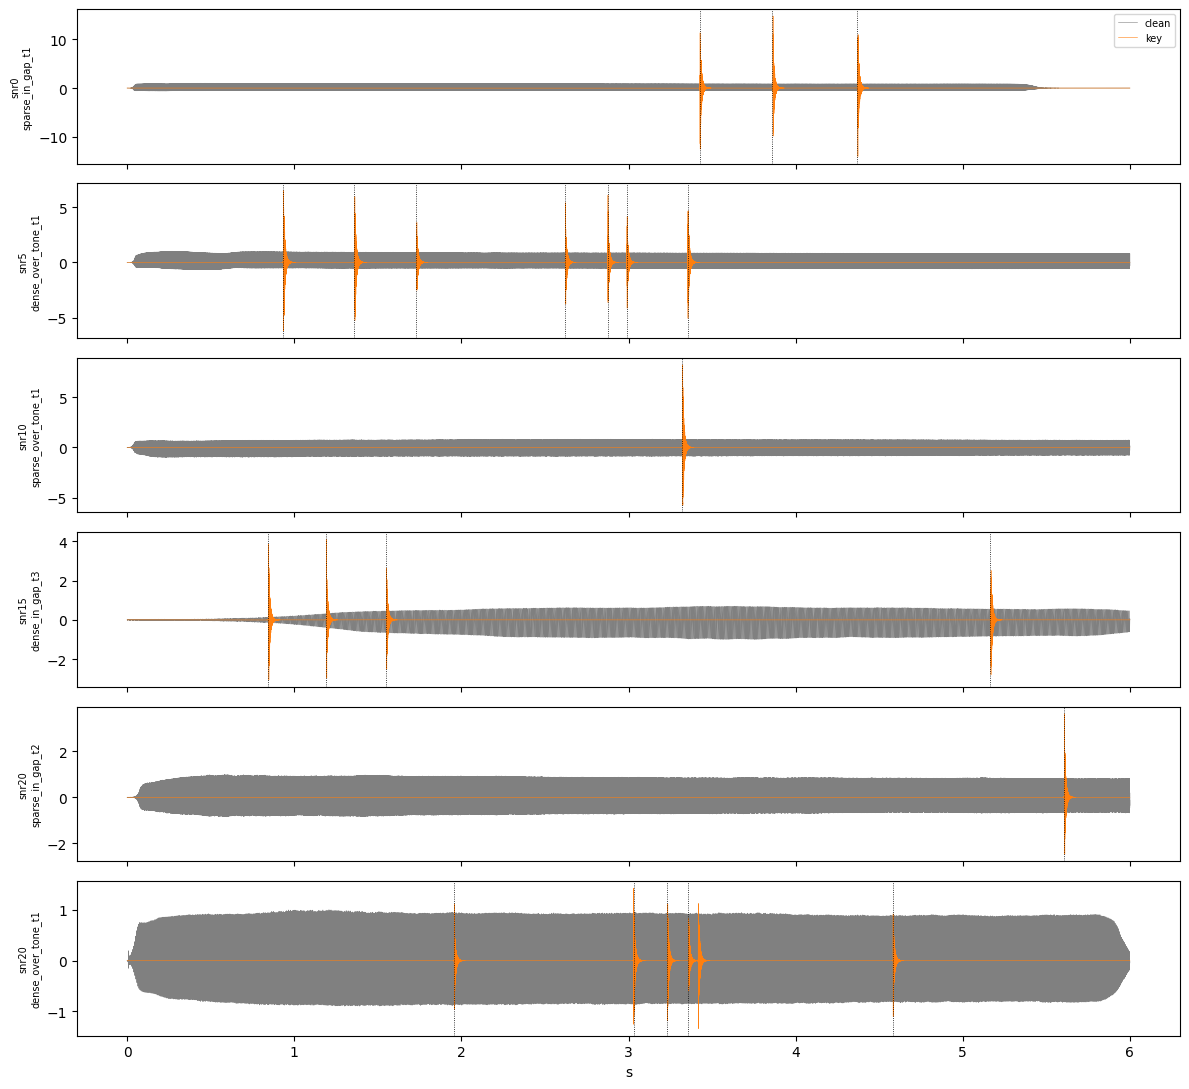

/Users/fuchienzou/.pyenv/versions/3.13.0/lib/python3.13/site-packages/matplotlib/axes/_axes.py:8283: RuntimeWarning: divide by zero encountered in log10
  Z = 10. * np.log10(spec)


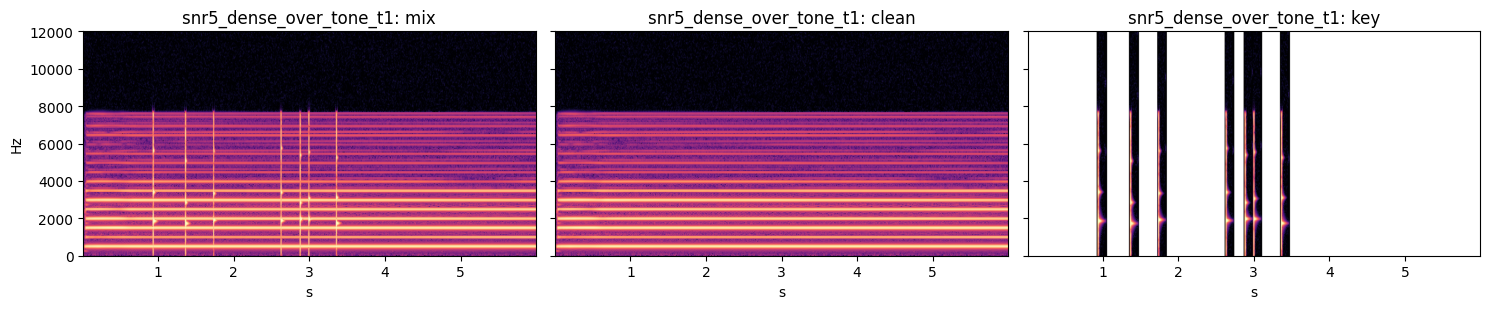

In [2]:
fig, ax = plt.subplots(len(CASES), 1, figsize=(12, 11), sharex=True)
for a_, (n, c) in zip(ax, CASES.items()):
    t = np.arange(c["mix"].size) / K.FS
    a_.plot(t, c["clean"], lw=.4, c=COLORS["clean"], label="clean")
    a_.plot(t, c["key"], lw=.4, c=COLORS["key"], label="key")
    for e in K.key_events(c["key"]): a_.axvline(e, c="k", lw=.6, ls=":")
    a_.set_ylabel(n.replace("_", "\n", 1), fontsize=7)
ax[0].legend(loc="upper right", fontsize=7); ax[-1].set_xlabel("s"); plt.tight_layout(); plt.show()

n0 = "snr5_dense_over_tone_t1"
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
for a_, k in zip(ax, ["mix", "clean", "key"]):
    a_.specgram(CASES[n0][k], NFFT=1024, Fs=K.FS, noverlap=768, vmin=-130, vmax=-30, cmap="magma")
    a_.set(title=f"{n0}: {k}", xlabel="s", ylim=(0, 12000))
ax[0].set_ylabel("Hz"); plt.tight_layout(); plt.show()

## 2. demo → rt system (KCS v23) → output

`sync` = worker drained after every callback (deterministic; same output as an infinitely fast worker).
Check vs the frozen demo output `02_output_v23_bridged` (KCS Python `Bridge48k` on the float input): LSB = one 16-bit step of the demo files.
The last 492 samples are excluded: KCS `finish()` (EOS) drops an unfinished repair; a live stream has no EOS, so rt keeps processing (SPEC §1.1).

In [3]:
runs = {}
for n, c in CASES.items():
    runs[n] = {"kcs": K.run("kcs-latest", c["mix"]), "kcs_clean": K.run("kcs-latest", c["clean"]),
               "pass": K.run("passthrough", c["mix"])}
print(f"{'case':28s} {'trig':>5} {'frozen':>6} {'fallback':>8} {'|rt-frozen| max':>16} {'p99':>6}  passthrough==mix")
for n, c in CASES.items():
    r = runs[n]; s = r["kcs"]["stats"]; lsb = 1 / 32767 / c["gain"]
    e = np.abs(r["kcs"]["y"] - c["frozen_out"])[:-492] / lsb
    print(f"{n:28s} {s['triggers']:>5} {c['frozen_triggers']:>6} {s['stats']['fallback_blocks']:>8} "
          f"{e.max():>12.2f} LSB {np.percentile(e, 99):>6.2f}  {np.array_equal(r['pass']['y'], c['mix'])}")

case                          trig frozen fallback  |rt-frozen| max    p99  passthrough==mix
snr0_sparse_in_gap_t1            4      4        0         1.63 LSB   0.71  True
snr5_dense_over_tone_t1          8      8        0         1.04 LSB   0.71  True
snr10_sparse_over_tone_t1        2      2        0         5.12 LSB   0.72  True
snr15_dense_in_gap_t3            4      4        0         6.17 LSB   0.73  True
snr20_sparse_in_gap_t2           3      3        0         1.02 LSB   0.71  True
snr20_dense_over_tone_t1         6      6        0         2.88 LSB   0.72  True


### 2b. listen

Players are 16 kHz (content stops at 8 kHz anyway; keeps the notebook small). Files: `notebook/out/kcs_<case>_{in,rt,clean}.wav` (48 kHz 16-bit, peak-normalised).

In [4]:
play = lambda x: Audio(resample_poly(np.asarray(x, np.float64), 1, 3), rate=16000)._repr_html_()
rows = ""
for n, c in CASES.items():
    y = runs[n]["kcs"]["y"]
    for tag, x in (("in", c["mix"]), ("rt", y), ("clean", c["clean"])): K.save_wav(f"kcs_{n}_{tag}", x)
    rows += f"<tr><th>{n}</th><td>{play(c['mix'])}</td><td>{play(y)}</td><td>{play(c['clean'])}</td></tr>"
display(HTML("<table><tr><th></th><th>input (mix)</th><th>rt output (KCS v23)</th><th>clean (reference)</th></tr>" + rows + "</table>"))

,input (mix),rt output (KCS v23),clean (reference)
snr0_sparse_in_gap_t1,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
snr5_dense_over_tone_t1,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
snr10_sparse_over_tone_t1,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
snr15_dense_in_gap_t3,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
snr20_sparse_in_gap_t2,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.
snr20_dense_over_tone_t1,Your browser does not support the audio element.,Your browser does not support the audio element.,Your browser does not support the audio element.


### 2c. real worker thread, 32-frame callbacks paced in real time (0.667 ms, ≈6 s wall per case)

Same cases with `ProcessingWorker` on its own thread. Blocks the worker misses are played dry (aligned) → listed as fallback; the output then differs from `sync` only in those blocks. Timing is machine/load dependent (not isolated).

In [5]:
print(f"{'case':28s} {'processed':>9} {'fallback':>8} {'stale':>5}  samples != sync")
for n, c in CASES.items():
    p = K.run("kcs-latest", c["mix"], mode="paced"); runs[n]["paced"] = p; s = p["stats"]["stats"]
    print(f"{n:28s} {s['processed_blocks']:>9} {s['fallback_blocks']:>8} {s['output_stale']:>5}  "
          f"{int(np.count_nonzero(p['y'] != runs[n]['kcs']['y']))}")

case                         processed fallback stale  samples != sync


snr0_sparse_in_gap_t1             8979       21     1  672


snr5_dense_over_tone_t1           8988       12     0  384


snr10_sparse_over_tone_t1         8974       26     0  832


snr15_dense_in_gap_t3             8991        9     0  288


snr20_sparse_in_gap_t2            8990       10     0  320


snr20_dense_over_tone_t1          8985       15     1  480


## 3. plots

Level (20 ms RMS) of input, rt output and clean; dotted = key onsets. Then a zoom on one key event and spectrograms before/after.

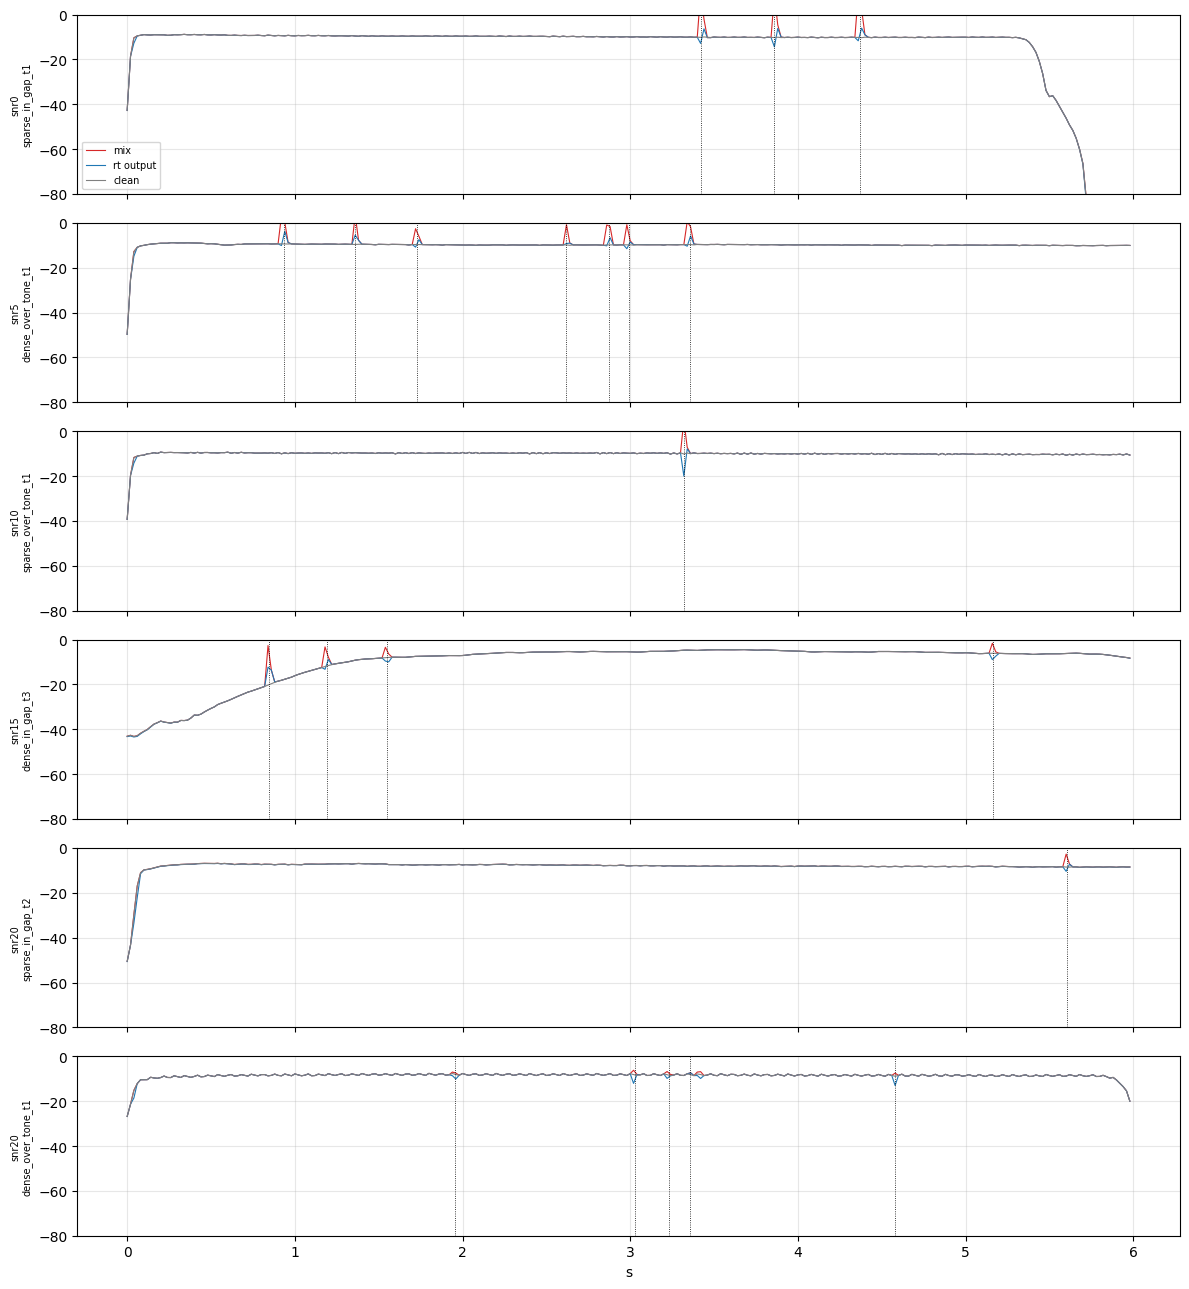

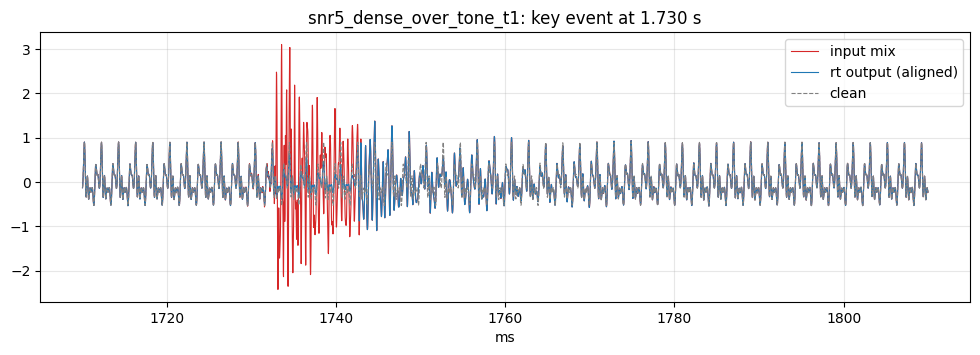

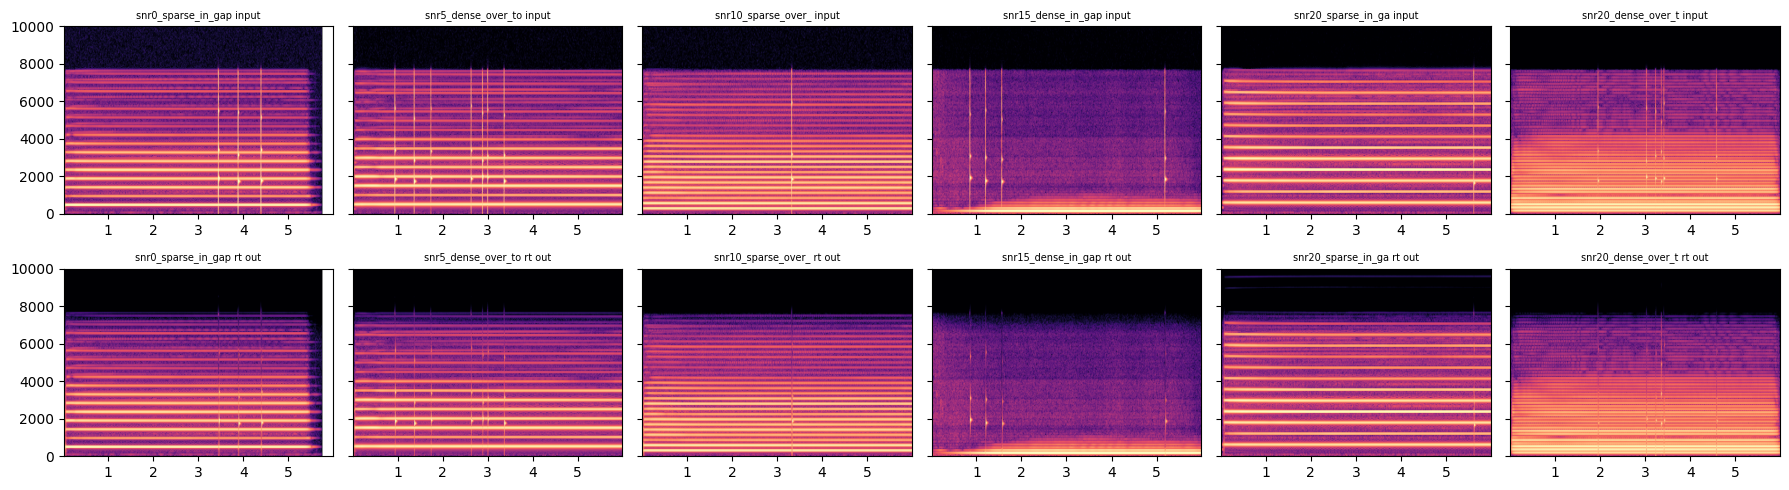

In [6]:
fig, ax = plt.subplots(len(CASES), 1, figsize=(12, 13), sharex=True)
for a_, (n, c) in zip(ax, CASES.items()):
    for k, x in (("mix", c["mix"]), ("kcs", runs[n]["kcs"]["y"]), ("clean", c["clean"])):
        t, d = K.rms_db(x); a_.plot(t, d, c=COLORS[k], lw=.8, label={"kcs": "rt output"}.get(k, k))
    for e in K.key_events(c["key"]): a_.axvline(e, c="k", lw=.6, ls=":")
    a_.set(ylim=(-80, 0)); a_.set_ylabel(n.replace("_", "\n", 1), fontsize=7); a_.grid(alpha=.3)
ax[0].legend(loc="lower left", fontsize=7); ax[-1].set_xlabel("s"); plt.tight_layout(); plt.show()

ev = K.key_events(CASES[n0]["key"])[2]
i0, i1 = int((ev - .02) * K.FS), int((ev + .08) * K.FS)
tt = np.arange(i0, i1) / K.FS * 1e3
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(tt, CASES[n0]["mix"][i0:i1], c=COLORS["mix"], lw=.8, label="input mix")
ax.plot(tt, runs[n0]["kcs"]["y"][i0:i1], c=COLORS["kcs"], lw=.8, label="rt output (aligned)")
ax.plot(tt, CASES[n0]["clean"][i0:i1], c=COLORS["clean"], lw=.8, ls="--", label="clean")
ax.set(xlabel="ms", title=f"{n0}: key event at {ev:.3f} s"); ax.legend(); ax.grid(alpha=.3); plt.show()

fig, ax = plt.subplots(2, len(CASES), figsize=(18, 5), sharey=True)
for j, (n, c) in enumerate(CASES.items()):
    for i, (k, x) in enumerate((("input", c["mix"]), ("rt out", runs[n]["kcs"]["y"]))):
        ax[i, j].specgram(x, NFFT=1024, Fs=K.FS, noverlap=768, vmin=-130, vmax=-30, cmap="magma")
        ax[i, j].set(ylim=(0, 10000)); ax[i, j].set_title(f"{n[:18]} {k}", fontsize=7)
plt.tight_layout(); plt.show()

### 3b. metrics (KCS frozen formulas, read-only import of `item3_score.py`)

- **KSR (D1)** = `energy_ksr(y_mix − y_clean, key)`, whole record. Compared with the frozen 16 kHz KSR in the demo README.
- **Clean run**: `lsd_db`, `seg_snr_db` (y_clean vs clean). Reference only: 48 kHz demo through the full bridge, not the frozen 16 kHz scoring.
- LSD here includes the bridge's 7 kHz low-pass (the clean run often has 0–2 triggers, yet LSD stays high) → band check below.

case                          KSR rt frozen16k    LSD  segSNR clean trig   out/in dB: 1–6k  6.5–7.5k  7.5–8k
snr0_sparse_in_gap_t1           97.5      97.5   6.90    34.8          1      -0.01     -5.2    -33.8
snr5_dense_over_tone_t1         87.6      87.6   5.40    34.9          1      -0.01     -8.8    -32.8
snr10_sparse_over_tone_t1       94.5      94.5   6.40    34.9          1      -0.01    -10.4    -29.8
snr15_dense_in_gap_t3           83.3      86.9   3.44    34.0          0      -0.01     -8.9    -30.5
snr20_sparse_in_gap_t2          87.8      87.8   4.75    28.2          2      -0.01    -12.6    -33.8
snr20_dense_over_tone_t1       -18.3     -24.2   4.60    34.9          1      -0.01     -8.4    -32.4


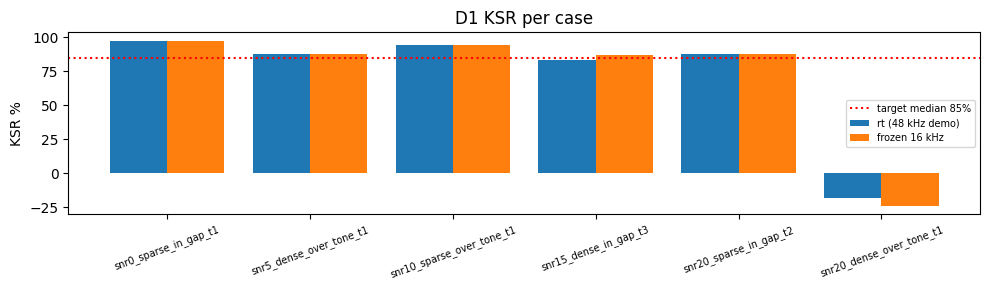

In [7]:
from scipy.signal import welch
rows = []
print(f"{'case':28s} {'KSR rt':>7} {'frozen16k':>9} {'LSD':>6} {'segSNR':>7} {'clean trig':>10}   out/in dB: 1–6k  6.5–7.5k  7.5–8k")
for n, c in CASES.items():
    m = K.metrics(SCORE, runs[n]["kcs"]["y"], runs[n]["kcs_clean"]["y"], c["clean"], c["key"])
    f, P = welch(c["clean"], K.FS, nperseg=4096); _, Q = welch(runs[n]["kcs_clean"]["y"], K.FS, nperseg=4096)
    band = lambda lo, hi: 10 * np.log10(Q[(f >= lo) & (f < hi)].mean() / P[(f >= lo) & (f < hi)].mean())
    rows.append((n, m["ksr"], K.FROZEN_KSR[n]))
    print(f"{n:28s} {m['ksr']:>7.1f} {K.FROZEN_KSR[n]:>9.1f} {m['lsd_db']:>6.2f} {m['seg_snr_db']:>7.1f} "
          f"{runs[n]['kcs_clean']['stats']['triggers']:>10}   {band(1e3, 6e3):+8.2f} {band(6.5e3, 7.5e3):+8.1f} {band(7.5e3, 8e3):+8.1f}")
fig, ax = plt.subplots(figsize=(10, 3))
x = np.arange(len(rows))
ax.bar(x - .2, [r[1] for r in rows], .4, label="rt (48 kHz demo)"); ax.bar(x + .2, [r[2] for r in rows], .4, label="frozen 16 kHz")
ax.axhline(85, ls=":", c="r", label="target median 85%"); ax.set_xticks(x, [r[0] for r in rows], rotation=20, fontsize=7)
ax.set(ylabel="KSR %", title="D1 KSR per case"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 4. latency per module + communication

- **audio path** = input→output delay of the code (contract E2E ≤30 ms = this + device in/out buffers, measured on a wired loopback).
- Compute time ≠ latency while it fits the callback period (2.667 ms @128); it only decides fallback risk.

core TransientAR32: 144 @16k = 9.000 ms
Pipeline48k (FIR + core + FIR): [492, 492, 492] @48k (3 phases) = 10.250 ms
Engine + KCS, hop  32: 544 frames = 11.333 ms
Engine + KCS, hop  64: 576 frames = 12.000 ms
Engine + KCS, hop 128: 640 frames = 13.333 ms


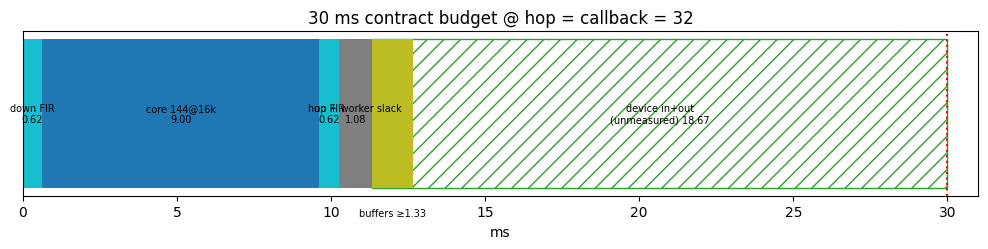

In [8]:
# 4a. audio-path latency: impulse per module, and through Engine for hop = callback 32/64/128
lat = {fr: K.latency(fr) for fr in (32, 64, 128)}
l = lat[32]   # default hop
print(f"core TransientAR32: {l['core_lag_16k']} @16k = {l['core_lag_16k'] / 16:.3f} ms")
print(f"Pipeline48k (FIR + core + FIR): {l['pipeline_lag_48k']} @48k (3 phases) = {l['pipeline_lag_48k'][0] / 48:.3f} ms")
for fr, v in lat.items(): print(f"Engine + KCS, hop {fr:>3}: {v['engine_lag_48k']} frames = {v['engine_lag_48k'] / 48:.3f} ms")
parts = [("down FIR", 30), ("core 144@16k", 3 * l["core_lag_16k"]), ("up FIR", 30),
         ("hop + worker slack", l["engine_lag_48k"] - l["pipeline_lag_48k"][0])]
fig, ax = plt.subplots(figsize=(10, 2.6)); left = 0
for (k, v), col in zip(parts, ["tab:cyan", "tab:blue", "tab:cyan", "tab:gray"]):
    ax.barh(0, v / 48, left=left, color=col); ax.text(left + v / 96, 0, f"{k}\n{v / 48:.2f}", ha="center", va="center", fontsize=7); left += v / 48
ax.barh(0, 30 - left, left=left, color="w", edgecolor="tab:green", hatch="//")
dev = 2 * 32 / 48   # in + out buffer floor at 32 frames
ax.barh(0, dev, left=left, color="tab:olive"); ax.text(left + dev / 2, -0.55, f"buffers ≥{dev:.2f}", ha="center", fontsize=7)
ax.text(left + (30 - left) / 2, 0, f"device in+out\n(unmeasured) {30 - left:.2f}", ha="center", va="center", fontsize=7)
ax.axvline(30, c="r", ls=":"); ax.set(xlabel="ms", yticks=[], xlim=(0, 31), title="30 ms contract budget @ hop = callback = 32")
plt.tight_layout(); plt.show()

engine_callback      n 13500  mean     0.92  p50     0.92  p99     1.08  max     13.1 us
pipeline_no_trigger  n 13470  mean    12.52  p50    12.58  p99    14.88  max     34.7 us
pipeline_trigger     n    30  mean   185.32  p50   192.33  p99   202.25  max    202.2 us
core_no_trigger      n 13469  mean     7.33  p50     7.38  p99     8.12  max     24.5 us
core_trigger         n    31  mean   176.11  p50   180.29  p99   208.17  max    208.2 us
on_audio             n 13500  mean    13.17  p50    12.88  p99    13.58  max    207.0 us
FIR 48↔16 (pipeline − core, no trigger) ≈ 5.19 us/block


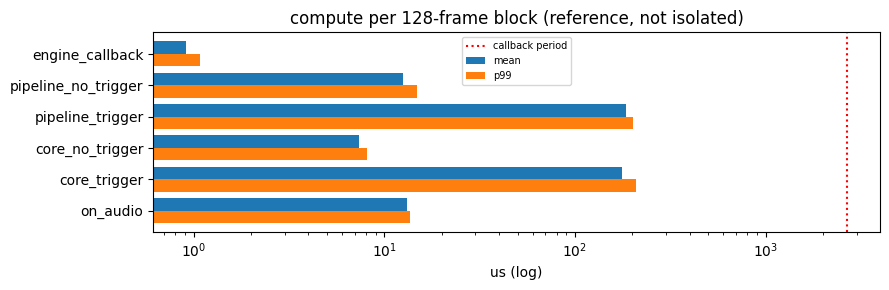

In [9]:
# 4b. compute per module, us per 128-frame block (budget 2667 us); input = all 6 mixes concatenated
allmix = np.concatenate([c["mix"] for c in CASES.values()])
st = K.stages(allmix)
order = ["engine_callback", "pipeline_no_trigger", "pipeline_trigger", "core_no_trigger", "core_trigger", "on_audio"]
for k in order: print(f"{k:<20} n {st[k]['n']:>5}  mean {st[k]['mean']:8.2f}  p50 {st[k]['p50']:8.2f}  p99 {st[k]['p99']:8.2f}  max {st[k]['max']:8.1f} us")
print(f"FIR 48↔16 (pipeline − core, no trigger) ≈ {st['pipeline_no_trigger']['mean'] - st['core_no_trigger']['mean']:.2f} us/block")
fig, ax = plt.subplots(figsize=(9, 3)); y = np.arange(len(order))
ax.barh(y - .2, [st[k]["mean"] for k in order], .4, label="mean"); ax.barh(y + .2, [st[k]["p99"] for k in order], .4, label="p99")
ax.axvline(2666.7, c="r", ls=":", label="callback period"); ax.set_xscale("log"); ax.set_yticks(y, order); ax.invert_yaxis()
ax.set(xlabel="us (log)", title="compute per 128-frame block (reference, not isolated)"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

blocks 13500  late (ready after its playback callback) 1  engine fallback 1 stale 0 input_dropped 0
Q_in transit (worker poll)         mean    157.95  p50    168.58  p99    268.79  max    1998.3 us
worker on_audio (KCS)              mean     55.14  p50     38.88  p99    101.17  max    1248.2 us
capture → block ready              mean    213.09  p50    220.33  p99    361.83  max    2033.8 us
ready → playback callback (slack)  mean   2448.10  p50   2445.96  p99   3052.62  max    4208.6 us


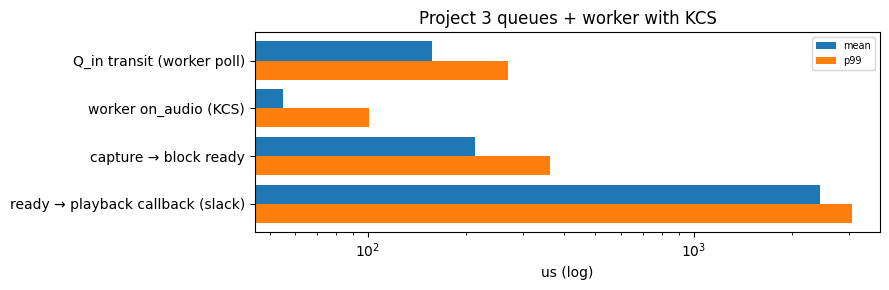

In [10]:
# 4c. communication: real Engine + ProcessingWorker, hop 128, callbacks paced 2.667 ms (~36 s wall)
cm = K.comm(allmix)
legs = ["q_in_transit", "worker", "capture_to_ready", "ready_to_playback"]
label = {"q_in_transit": "Q_in transit (worker poll)", "worker": "worker on_audio (KCS)",
         "capture_to_ready": "capture → block ready", "ready_to_playback": "ready → playback callback (slack)"}
s = cm["stats"]
print(f"blocks {cm['blocks']}  late (ready after its playback callback) {cm['late_blocks']}  "
      f"engine fallback {s['fallback_blocks']} stale {s['output_stale']} input_dropped {s['input_dropped']}")
for k in legs: print(f"{label[k]:<34} mean {cm[k]['mean']:9.2f}  p50 {cm[k]['p50']:9.2f}  p99 {cm[k]['p99']:9.2f}  max {cm[k]['max']:9.1f} us")
fig, ax = plt.subplots(figsize=(9, 3)); y = np.arange(len(legs))
ax.barh(y - .2, [abs(cm[k]["mean"]) for k in legs], .4, label="mean"); ax.barh(y + .2, [abs(cm[k]["p99"]) for k in legs], .4, label="p99")
ax.set_yticks(y, [label[k] for k in legs]); ax.set_xscale("log"); ax.invert_yaxis()
ax.set(xlabel="us (log)", title="Project 3 queues + worker with KCS"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

### 4d. lower latency: hop = callback 128 / 64 / 32

No algorithm change: only the worker hop and the device callback shrink. Delay = smallest callback multiple ≥ hop + 492 (`kcs::minimum_delay_frames`). The worker's budget per block shrinks with the hop (2.667 / 1.333 / 0.667 ms); a trigger block costs ~0.2 ms. Device in+out buffer floor = 2 × callback (5.33 / 2.67 / 1.33 ms, not measured). 3 paced runs per hop (stalls are random → read the spread, not one run). ~6 min wall.

hop 128: delay 13.333 ms  buffer floor  5.33 ms  sum  18.67 ms  output == hop128: True  paced fallback % [0.04, 0.02, 0.07] (median 0.04)  capture→ready p50 230 us, worst max 4.7 ms (budget 2667 us)


hop  64: delay 12.000 ms  buffer floor  2.67 ms  sum  14.67 ms  output == hop128: True  paced fallback % [0.89, 0.85, 0.39] (median 0.85)  capture→ready p50 186 us, worst max 30.2 ms (budget 1333 us)


hop  32: delay 11.333 ms  buffer floor  1.33 ms  sum  12.67 ms  output == hop128: True  paced fallback % [0.18, 0.48, 0.62] (median 0.48)  capture→ready p50 147 us, worst max 10.6 ms (budget 667 us)


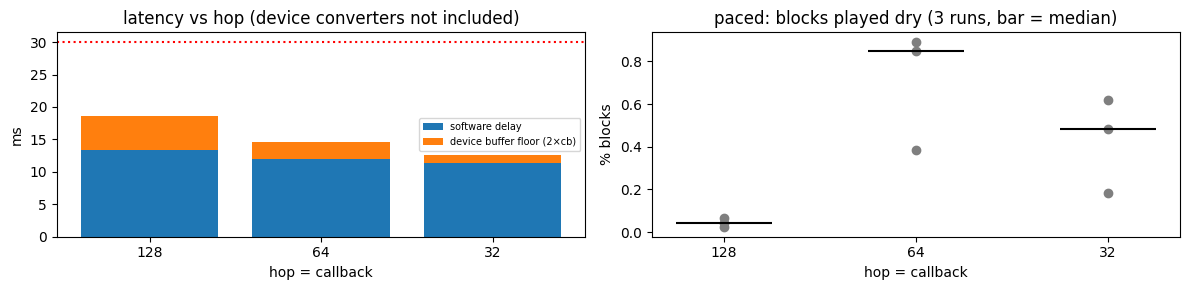

In [11]:
REPS = 3
ref = {n: K.run("kcs-latest", c["mix"], 128)["y"] for n, c in CASES.items()}
sweep = {}
for hop in (128, 64, 32):
    same = all(np.array_equal(K.run("kcs-latest", c["mix"], hop)["y"], ref[n]) for n, c in CASES.items())
    cms = [K.comm(allmix, hop) for _ in range(REPS)]
    fb = [100 * m["stats"]["fallback_blocks"] / m["blocks"] for m in cms]
    sweep[hop] = dict(delay=lat[hop]["engine_lag_48k"] / 48, buf=2 * hop / 48, fb=fb, same=same,
                      ready_p50=[m["capture_to_ready"]["p50"] for m in cms], ready_max=[m["capture_to_ready"]["max"] for m in cms])
    v = sweep[hop]
    print(f"hop {hop:>3}: delay {v['delay']:6.3f} ms  buffer floor {v['buf']:5.2f} ms  sum {v['delay'] + v['buf']:6.2f} ms  "
          f"output == hop128: {same}  paced fallback % {[round(f, 2) for f in fb]} (median {np.median(fb):.2f})  "
          f"capture→ready p50 {np.median(v['ready_p50']):.0f} us, worst max {max(v['ready_max']) / 1000:.1f} ms (budget {hop / 48 * 1000:.0f} us)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
hops = list(sweep)
ax[0].bar([str(h) for h in hops], [sweep[h]["delay"] for h in hops], label="software delay")
ax[0].bar([str(h) for h in hops], [sweep[h]["buf"] for h in hops], bottom=[sweep[h]["delay"] for h in hops], label="device buffer floor (2×cb)")
ax[0].axhline(30, c="r", ls=":"); ax[0].set(xlabel="hop = callback", ylabel="ms", title="latency vs hop (device converters not included)"); ax[0].legend(fontsize=7)
for k, h in enumerate(hops):
    ax[1].scatter([k] * REPS, sweep[h]["fb"], c="tab:gray"); ax[1].hlines(np.median(sweep[h]["fb"]), k - .25, k + .25, color="k")
ax[1].set_xticks(range(len(hops)), [str(h) for h in hops])
ax[1].set(xlabel="hop = callback", ylabel="% blocks", title=f"paced: blocks played dry ({REPS} runs, bar = median)")
plt.tight_layout(); plt.show()

## 6. report figures

Two summary figures for the write-up, saved to `notebook/out/report/` (PNG, 150 dpi).
- **correctness**: C++ port vs KCS Python on synthetic signals (`equivalence_results.json`), rt system vs frozen demo output, trigger counts, D1 KSR.
- **latency**: budget per hop vs 30 ms, compute per module vs callback period, fallback spread per hop.

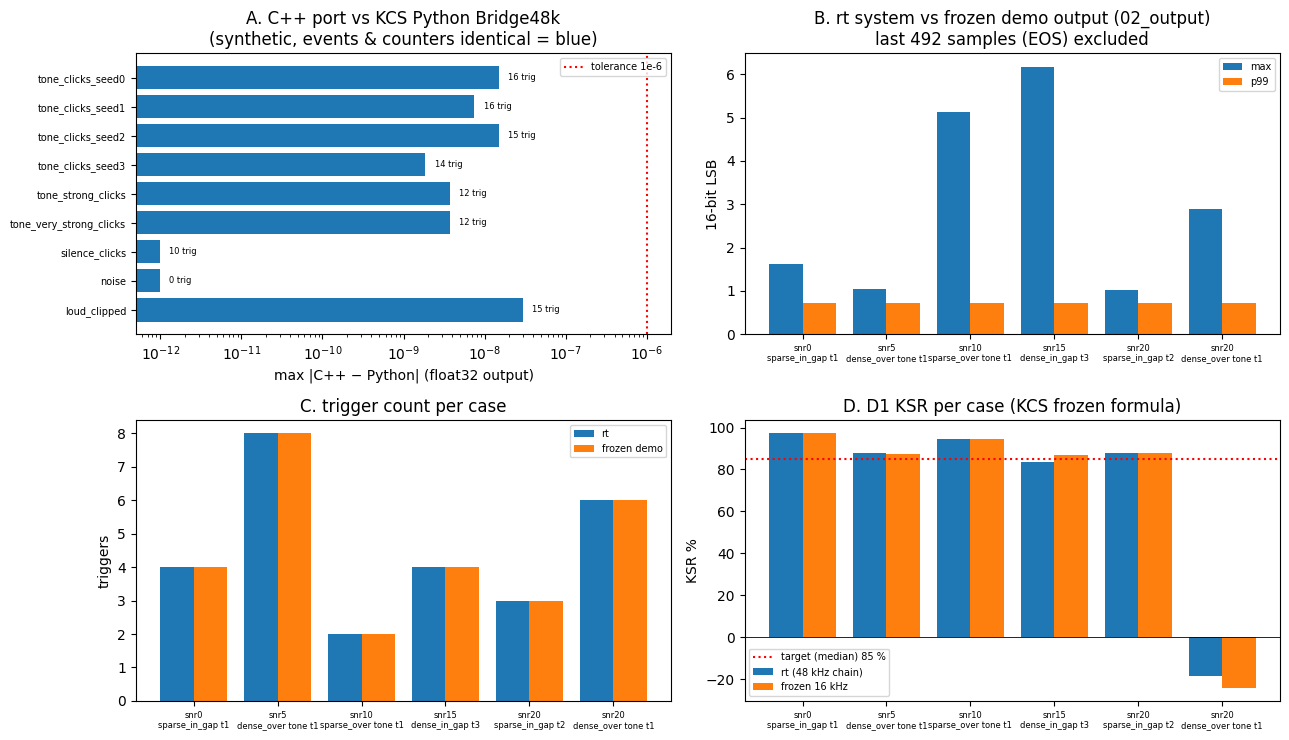

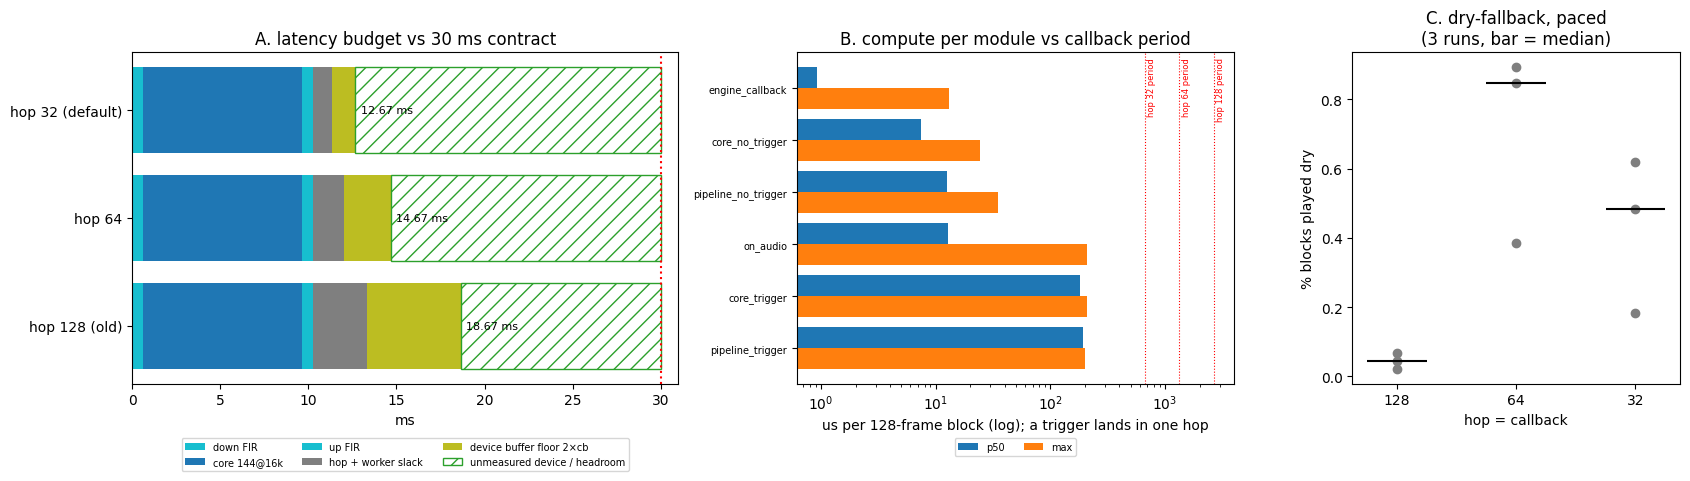

['correctness.png', 'latency.png']


In [12]:
import json
REPORT = K.OUT / "report"; REPORT.mkdir(exist_ok=True)
eq = json.loads((K.ROOT / "release/kcs/kcs-v23-ce6237c12/equivalence_results.json").read_text())["results"]
names = list(CASES); short = [n.replace("_t", " t").replace("_", "\n", 1) for n in names]

# --- correctness -------------------------------------------------------------
fig, ax = plt.subplots(2, 2, figsize=(13, 7.5))
a = ax[0, 0]
sig = [r["signal"] for r in eq]; err = [max(r["max_abs_error"], 1e-12) for r in eq]
a.barh(range(len(eq)), err, color=["tab:blue" if r["events_identical"] and r["counters_identical"] else "tab:red" for r in eq])
a.set_yticks(range(len(eq)), sig, fontsize=7); a.set_xscale("log"); a.invert_yaxis(); a.axvline(1e-6, c="r", ls=":", label="tolerance 1e-6")
a.set(xlabel="max |C++ − Python| (float32 output)", title="A. C++ port vs KCS Python Bridge48k\n(synthetic, events & counters identical = blue)")
for k, r in enumerate(eq): a.text(err[k] * 1.3, k, f"{r['events_cpp']} trig", va="center", fontsize=6)
a.legend(fontsize=7)

a = ax[0, 1]
mx, p99 = [], []
for n in names:
    c = CASES[n]; lsb = 1 / 32767 / c["gain"]; e = np.abs(runs[n]["kcs"]["y"] - c["frozen_out"])[:-492] / lsb
    mx.append(e.max()); p99.append(np.percentile(e, 99))
x = np.arange(len(names))
a.bar(x - .2, mx, .4, label="max"); a.bar(x + .2, p99, .4, label="p99")
a.set_xticks(x, short, fontsize=6); a.set(ylabel="16-bit LSB", title="B. rt system vs frozen demo output (02_output)\nlast 492 samples (EOS) excluded"); a.legend(fontsize=7)

a = ax[1, 0]
tr = [runs[n]["kcs"]["stats"]["triggers"] for n in names]; fz = [CASES[n]["frozen_triggers"] for n in names]
a.bar(x - .2, tr, .4, label="rt"); a.bar(x + .2, fz, .4, label="frozen demo")
a.set_xticks(x, short, fontsize=6); a.set(ylabel="triggers", title="C. trigger count per case"); a.legend(fontsize=7)

a = ax[1, 1]
ksr = [K.metrics(SCORE, runs[n]["kcs"]["y"], runs[n]["kcs_clean"]["y"], CASES[n]["clean"], CASES[n]["key"])["ksr"] for n in names]
a.bar(x - .2, ksr, .4, label="rt (48 kHz chain)"); a.bar(x + .2, [K.FROZEN_KSR[n] for n in names], .4, label="frozen 16 kHz")
a.axhline(85, c="r", ls=":", label="target (median) 85 %"); a.axhline(0, c="k", lw=.6)
a.set_xticks(x, short, fontsize=6); a.set(ylabel="KSR %", title="D. D1 KSR per case (KCS frozen formula)"); a.legend(fontsize=7)
plt.tight_layout(); fig.savefig(REPORT / "correctness.png", dpi=150); plt.show()

# --- latency -------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.5, 1.2, 0.9]})
a = ax[0]
segs = [("down FIR", 30 / 48, "tab:cyan"), ("core 144@16k", 432 / 48, "tab:blue"), ("up FIR", 30 / 48, "tab:cyan")]
for k, h in enumerate((128, 64, 32)):
    left = 0
    for lab, v, col in segs:
        a.barh(k, v, left=left, color=col, label=lab if k == 0 else None); left += v
    hs = sweep[h]["delay"] - left
    a.barh(k, hs, left=left, color="tab:gray", label="hop + worker slack" if k == 0 else None); left += hs
    a.barh(k, sweep[h]["buf"], left=left, color="tab:olive", label="device buffer floor 2×cb" if k == 0 else None); left += sweep[h]["buf"]
    a.barh(k, 30 - left, left=left, color="w", edgecolor="tab:green", hatch="//", label="unmeasured device / headroom" if k == 0 else None)
    a.text(left + .3, k, f"{left:.2f} ms", va="center", fontsize=8)
a.set_yticks(range(3), ["hop 128 (old)", "hop 64", "hop 32 (default)"]); a.axvline(30, c="r", ls=":")
a.set(xlabel="ms", xlim=(0, 31), title="A. latency budget vs 30 ms contract"); a.legend(fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.15), ncol=3)

a = ax[1]
order = ["engine_callback", "core_no_trigger", "pipeline_no_trigger", "on_audio", "core_trigger", "pipeline_trigger"]
y = np.arange(len(order))
a.barh(y - .2, [st[k]["p50"] for k in order], .4, label="p50"); a.barh(y + .2, [st[k]["max"] for k in order], .4, label="max")
for b, lab in ((2666.7, "128"), (1333.3, "64"), (666.7, "32")): a.axvline(b, c="r", ls=":", lw=.8); a.text(b * 1.05, -.6, f"hop {lab} period", fontsize=6, color="r", rotation=90, va="top")
a.set_yticks(y, order, fontsize=7); a.set_xscale("log"); a.invert_yaxis()
a.set(xlabel="us per 128-frame block (log); a trigger lands in one hop", title="B. compute per module vs callback period"); a.legend(fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.15), ncol=2)

a = ax[2]
for k, h in enumerate((128, 64, 32)):
    a.scatter([k] * len(sweep[h]["fb"]), sweep[h]["fb"], c="tab:gray"); a.hlines(np.median(sweep[h]["fb"]), k - .25, k + .25, color="k")
a.set_xticks(range(3), ["128", "64", "32"])
a.set(xlabel="hop = callback", ylabel="% blocks played dry", title=f"C. dry-fallback, paced\n({REPS} runs, bar = median)")
plt.tight_layout(); fig.savefig(REPORT / "latency.png", dpi=150); plt.show()
print(sorted(p.name for p in REPORT.glob("*.png")))

## 5. read-out

Run 2026-11-12, Local Mac (Apple M5, macOS arm64, Apple clang 17 `-O2`), KCS scorer @ `ce6237c`. Load avg 2.6–4.5, other apps running → timing = reference only.

- **System = KCS reference.** All 6 demo cases through the real Engine + KCS: same trigger counts as the frozen demo; output vs `02_output_v23_bridged` ≤ 6.2 LSB of the 16-bit files (p99 ≈ 0.7 LSB, i.e. input quantisation), last 492 samples excluded (KCS `finish()` EOS; live stream has none). Passthrough = input exactly.
- **KSR (D1, frozen formula):** 4 cases equal the frozen 16 kHz numbers (97.5 / 87.6 / 94.5 / 87.8). `snr15_dense_in_gap_t3` 83.3 (frozen 86.9) and `snr20_dense_over_tone_t1` −18.3 (frozen −24.2): KCS's own Python `Bridge48k` gives the same 83.3 / −18.3 on these files → difference = 48 kHz chain vs frozen 16 kHz scoring, not the rt port. The known failure case still fails.
- **Clean run:** seg SNR 28–35 dB; LSD 3.4–6.9 dB is the bridge's 7 kHz low-pass (−5…−13 dB at 6.5–7.5 kHz, ≈ −30 dB at 7.5–8 kHz, 1–6 kHz −0.01 dB), present even with 0 triggers. Not comparable to the frozen 0.00 dB (16 kHz core only). Bridge filter is a KCS design choice.
- **Latency (impulse):** core 144 @16k = 9.000 ms; Pipeline48k 492 = 10.250 ms (all 3 phases); Engine + KCS = 544 / 576 / 640 frames = **11.33** / 12.00 / 13.33 ms for hop = callback 32 / 64 / 128.
- **Lowered (§4d), no algorithm change:** default hop = callback 32 (was 128): software delay −2.00 ms; device buffer floor 2×callback 5.33 → 1.33 ms (−4 ms, not measured). Output identical for every hop. Remaining for device in+out within 30 ms: 18.67 ms at hop 32 (unmeasured; needs wired interface + loopback).
- **Fallback vs hop** (paced, not isolated): this run (§4d, 3 each) median 0.04 / 0.85 / 0.48 % for hop 128 / 64 / 32; over 11 runs per hop across the session 0.27 / 0.46 / 0.42 % (ranges 0–0.56 / 0.01–2.00 / 0.07–1.27 %). Ranges overlap; hop 32 may be slightly worse than 128. Driven by thread scheduling stalls (up to ~94 ms), not compute → fix belongs to worker priority / wake-up.
- **Not lowered yet:** core 144 @16k (9 ms, KCS v23 design → needs a new KCS version + prediction) and the 61-tap FIRs (1.25 ms, could be redesigned as a release-adapter change with its own verification).
- **Compute per 128-frame block:** callback 0.9 µs; KCS without trigger ≈ 13 µs (core 7.3, FIRs ≈ 5.2); with trigger (AR32 fit + roots) ≈ 185 µs, max 221 µs → < 9 % of the 2.667 ms budget.
- **Real worker, paced (hop 128, §4c):** capture → ready p50 ≈ 230 µs (mostly the worker's 200 µs poll), p99 ≈ 360 µs; occasional scheduling stalls make blocks fall back to dry (see §4d for the distribution). 2c (hop 32): 1–11 fallback blocks per case.
- Material is synthetic (TinySOL + synthetic clicks, 16 kHz upsampled); dev-set numbers, not acceptance.
- Outputs: `notebook/out/kcs_<case>_{in,rt,clean}.wav`, `kcs_*_out.f32`.
